# Project 4: Image Recognition on MNIST Dataset

Welcome to the **MNIST Digit Recognition** Jupyter Notebook. This project demonstrates a complete workflow for training a deep learning model to recognize handwritten digits (0-9) from the famous MNIST dataset. 

### Goal
Build and train a Convolutional Neural Network (CNN) using **TensorFlow/Keras** to achieve high accuracy in digit classification, evaluate its performance, and visualize its predictions.

### Pipeline Overview
1. **Environment Setup & Imports**: Loading standard data science and deep learning libraries.
2. **Exploratory Data Analysis (EDA)**: Visualizing sample digits from the dataset.
3. **Data Preprocessing**: Preparing and normalizing image data for neural network training.
4. **Model Architecture**: Creating a Convolutional Neural Network (CNN).
5. **Model Training**: Compiling and fitting the model on training data.
6. **Evaluation & Performance Analysis**: Plotting learning curves, calculating classification metrics, and plotting a confusion matrix.
7. **Visual Inference**: Visualizing predictions on sample test images alongside confidence distributions.

---  
## 1. Setup & Import Libraries
We start by importing the necessary libraries including TensorFlow, NumPy, Matplotlib, Seaborn, and Scikit-learn.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# TensorFlow and Keras
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

# Set style for visualizations
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.19.0


---  
## 2. Load the Dataset
The MNIST dataset is built into Keras, making it convenient to load. We will split it into training (60,000 images) and testing (10,000 images) sets.

In [2]:
# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print(f"Training images shape: {X_train.shape}")
print(f"Training labels shape: {y_train.shape}")
print(f"Test images shape: {X_test.shape}")
print(f"Test labels shape: {y_test.shape}")

       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/11490434 ━━━━━━━━━━━━━━━━━━━━ 38s 3us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 38s 3us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 36s 3us/step

  147456/11490434 ━━━━━━━━━━━━━━━━━━━━ 24s 2us/step

  180224/11490434 ━━━━━━━━━━━━━━━━━━━━ 23s 2us/step

... (57 outputs left out)

11141120/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11378688/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)


---  
## 3. Exploratory Data Analysis (EDA)
Let's display some sample images from the training dataset to understand the input structure.

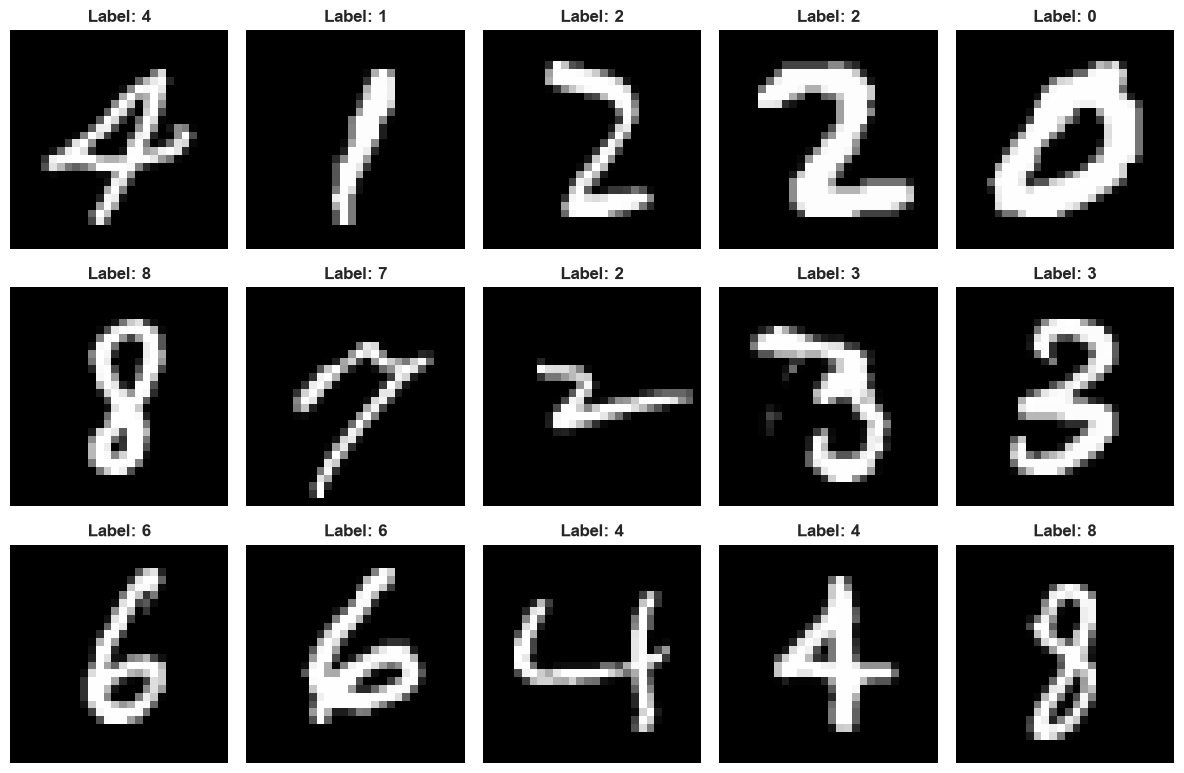

In [3]:
# Plot sample digits
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
axes = axes.ravel()

for i in range(15):
    idx = np.random.randint(0, len(X_train))
    axes[i].imshow(X_train[idx], cmap="gray")
    axes[i].set_title(f"Label: {y_train[idx]}", fontsize=12, fontweight="bold")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

---  
## 4. Data Preprocessing
To prepare our data for a Convolutional Neural Network, we need to:
1. **Reshape the images** to add the single channel dimension (from `(28, 28)` to `(28, 28, 1)`).
2. **Normalize pixel values** from the range `[0, 255]` to `[0.0, 1.0]`. Normalization helps the optimization algorithm converge much faster.

In [4]:
# Normalize pixel values
X_train_scaled = X_train.astype("float32") / 255.0
X_test_scaled = X_test.astype("float32") / 255.0

# Reshape data to include channel dimension (height, width, channels)
X_train_scaled = np.expand_dims(X_train_scaled, axis=-1)
X_test_scaled = np.expand_dims(X_test_scaled, axis=-1)

print(f"Preprocessed training shape: {X_train_scaled.shape}")
print(f"Preprocessed test shape: {X_test_scaled.shape}")

Preprocessed training shape: (60000, 28, 28, 1)
Preprocessed test shape: (10000, 28, 28, 1)


---  
## 5. Model Architecture Design
We will design a simple yet powerful **Convolutional Neural Network (CNN)**. CNNs are highly effective for image classification tasks because they exploit spatial relationships in local features.

The network consists of:
- **Conv2D Layer**: Learns spatial features.
- **MaxPooling2D Layer**: Downsamples features to reduce computational complexity and prevent overfitting.
- **Flatten Layer**: Flattens the 2D feature map into a 1D vector.
- **Dense Layers**: Fully connected layers for classification.
- **Dropout Layer**: Regularization technique that randomly disables neurons during training.

In [5]:
def build_cnn_model():
    model = models.Sequential([
        # First Convolutional Block
        layers.Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
        layers.MaxPooling2D((2, 2)),
        
        # Second Convolutional Block
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        
        # Flattening
        layers.Flatten(),
        
        # Fully Connected Layers
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax") # Softmax output for 10 classes
    ])
    
    return model

model = build_cnn_model()
model.summary()

D:\Apps\pythonnn\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

---  
## 6. Compile & Train the Model
We compile the model with the **Adam optimizer** and **Sparse Categorical Crossentropy** loss. We also include an **EarlyStopping callback** to stop training when validation loss stops improving, avoiding overfitting.

In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Early Stopping to prevent overfitting
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train_scaled, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop]
)

Epoch 1/10


  1/844 ━━━━━━━━━━━━━━━━━━━━ 37:13 3s/step - accuracy: 0.1719 - loss: 2.2977

  3/844 ━━━━━━━━━━━━━━━━━━━━ 21s 26ms/step - accuracy: 0.1910 - loss: 2.2758

  6/844 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.2053 - loss: 2.2584

  9/844 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - accuracy: 0.2206 - loss: 2.2339

 12/844 ━━━━━━━━━━━━━━━━━━━━ 17s 21ms/step - accuracy: 0.2374 - loss: 2.2074

... (2,767 outputs left out)

836/844 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9929 - loss: 0.0217

840/844 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9929 - loss: 0.0217

843/844 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9929 - loss: 0.0217

844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 19ms/step - accuracy: 0.9928 - loss: 0.0229 - val_accuracy: 0.9918 - val_loss: 0.0333


---  
## 7. Model Evaluation
Let's evaluate the model's accuracy on the test set and plot the loss and accuracy curves.

In [7]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 0.9911
Test Loss: 0.0251


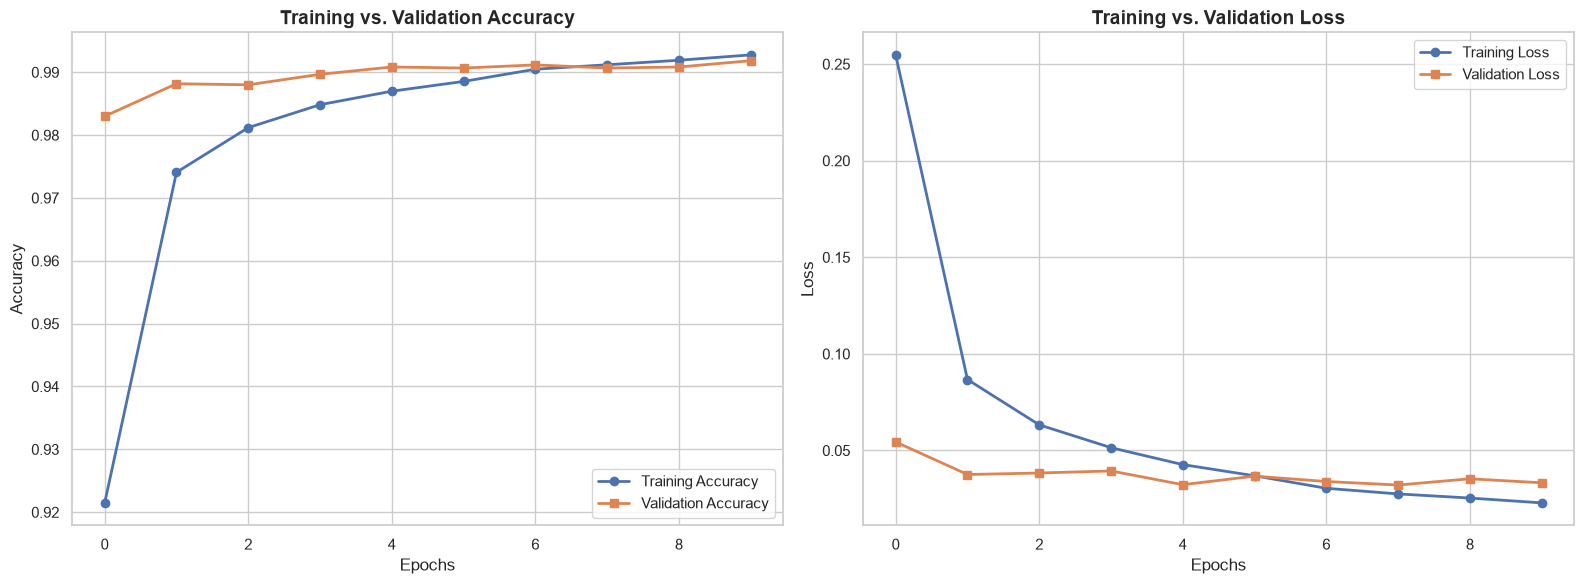

In [8]:
# Plot training & validation metrics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy curve
ax1.plot(history.history["accuracy"], label="Training Accuracy", linewidth=2, marker="o")
ax1.plot(history.history["val_accuracy"], label="Validation Accuracy", linewidth=2, marker="s")
ax1.set_title("Training vs. Validation Accuracy", fontsize=14, fontweight="bold")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Accuracy")
ax1.legend()
ax1.grid(True)

# Loss curve
ax2.plot(history.history["loss"], label="Training Loss", linewidth=2, marker="o")
ax2.plot(history.history["val_loss"], label="Validation Loss", linewidth=2, marker="s")
ax2.set_title("Training vs. Validation Loss", fontsize=14, fontweight="bold")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Loss")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

---  
## 8. Classification Metrics & Confusion Matrix
Let's look at precision, recall, and f1-score for each digit class and plot the confusion matrix.

In [9]:
# Make predictions
y_pred_probs = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_probs, axis=1)

# Classification report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

  1/313 ━━━━━━━━━━━━━━━━━━━━ 31s 102ms/step

 12/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step   

 27/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

 39/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

 54/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

 67/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step

... (16 outputs left out)

304/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step



Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       1.00      0.99      1.00      1135
           2       1.00      0.98      0.99      1032
           3       0.99      0.99      0.99      1010
           4       1.00      1.00      1.00       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.97      1.00      0.98      1028
           8       1.00      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



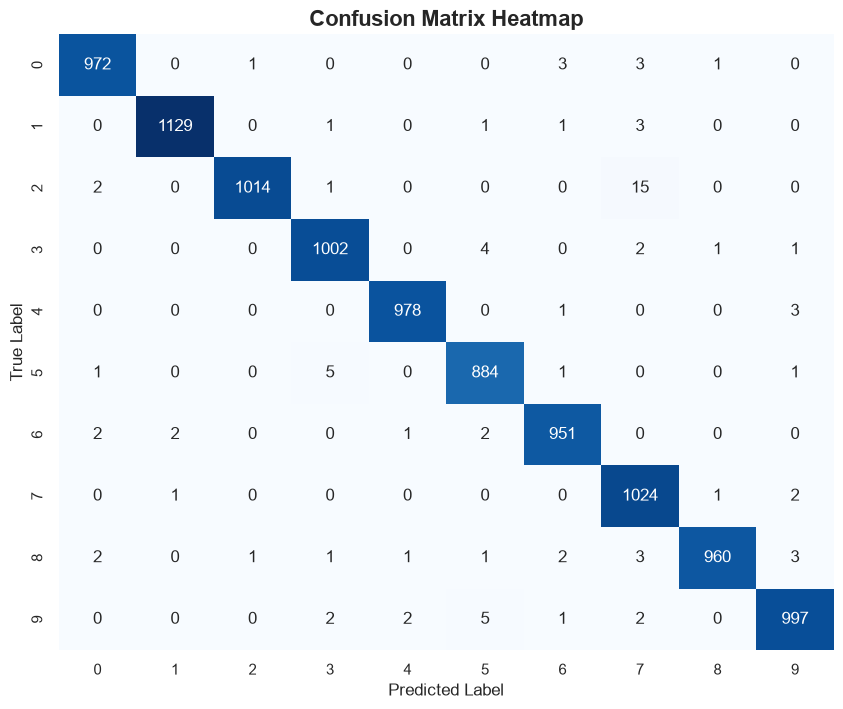

In [10]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=list(range(10)), yticklabels=list(range(10)))
plt.title("Confusion Matrix Heatmap", fontsize=16, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.show()

---  
## 9. Visual Inference Demonstration
Finally, we can visualize predictions on random test digits with prediction confidence bars.

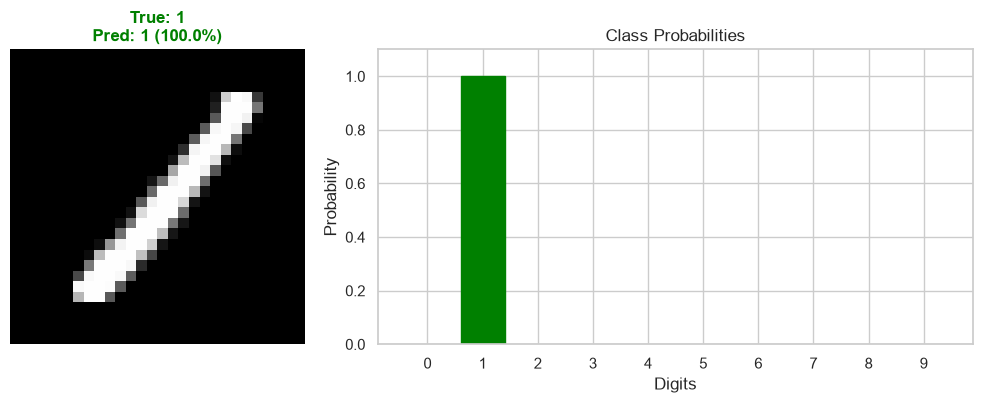

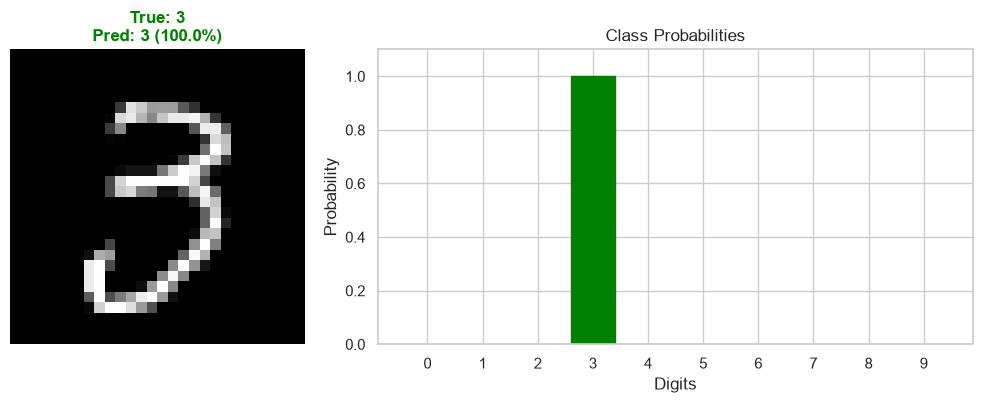

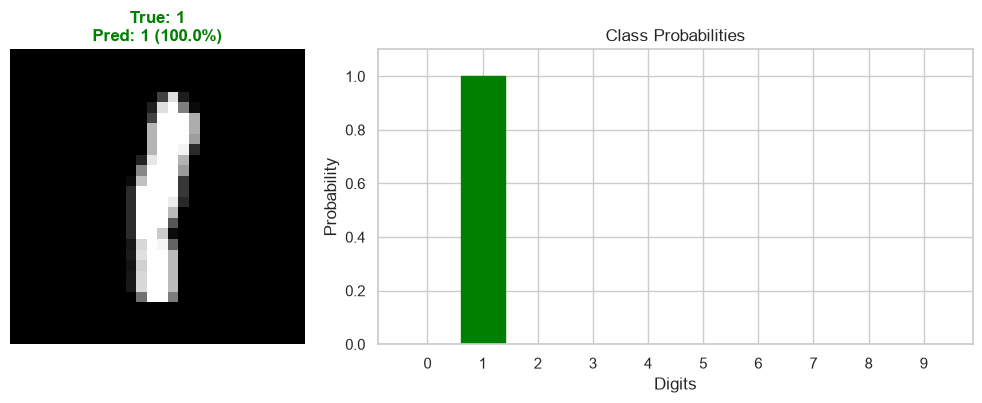

In [11]:
# Pick random indices
num_samples = 3
indices = np.random.choice(len(X_test), num_samples, replace=False)

for i, idx in enumerate(indices):
    img = X_test[idx]
    true_label = y_test[idx]
    pred_probs = y_pred_probs[idx]
    pred_label = np.argmax(pred_probs)
    
    # Create figure
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={'width_ratios': [1, 2]})
    
    # Image Display
    ax1.imshow(img, cmap="gray")
    title_color = "green" if pred_label == true_label else "red"
    ax1.set_title(f"True: {true_label}\nPred: {pred_label} ({pred_probs[pred_label]*100:.1f}%)",
                  color=title_color, fontsize=12, fontweight="bold")
    ax1.axis("off")
    
    # Probability Bar Chart
    bars = ax2.bar(range(10), pred_probs, color="#a0c4ff")
    bars[pred_label].set_color("green" if pred_label == true_label else "red")
    ax2.set_xticks(range(10))
    ax2.set_ylim(0, 1.1)
    ax2.set_title("Class Probabilities", fontsize=12)
    ax2.set_xlabel("Digits")
    ax2.set_ylabel("Probability")
    
    plt.tight_layout()
    plt.show()